In [1]:
"""
this will turn into a script
copied from implanting_full_again_LOTS but we are also dimming this time
we're gonna implant transients in a buncha new images
about 10 per image

we are also gonna save half as implanted images and half will be broken up
into training stamps

copying some from implanting_transients_full_ and implanting_full_again
"""

"\nthis will turn into a script\ncopied from implanting_full_again_LOTS but we are also dimming this time\nwe're gonna implant transients in a buncha new images\nabout 10 per image\n\nwe are also gonna save half as implanted images and half will be broken up\ninto training stamps\n\ncopying some from implanting_transients_full_ and implanting_full_again\n"

In [2]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import imageio as iio
from astropy.io import fits
import os
import pandas as pd

In [3]:
import review_findings_functions as ff

In [4]:
import implantation_functions as imp

In [5]:
import importlib

In [5]:
importlib.reload(imp)

<module 'implantation_functions' from '/home/3155/implantation_functions.py'>

In [6]:
# some matplotlib defaults
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [7]:
# some stuff that will stay the same
wid = 10
# fpath_image = "/lustre/lrspec/ZTF_data/2022_1014_copy/to_implant_full/"
# fpath_info = "/lustre/lrspec/ZTF_data/2022_1014_copy/info_for_images_with_implanted_transients/"

# image_directory = os.fsencode(fpath_image)

In [9]:
# #getting a training file
# fpath = "/lustre/lrspec/ZTF_data/2022/" #20210622_copy/to_implant/"
# #hdul=fits.open(fpath+"ztf_20210622237812_000677_zr_c12_o_0051.fits.fz")
# hdul=fits.open(fpath+"1014/ztf_20221014162894_000802_zg_c03_x_0015.fits.fz")
# file1_array = hdul[1].data
# norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array))

In [10]:
# plt.imshow(np.sqrt(norm))

In [11]:
def show_streak(image, streak_x_val, center_value_y=None):
    plt.imshow(np.sqrt(image), aspect=0.05)
    plt.xlim(streak_x_val - 10, streak_x_val + 10)
    # plt.ylim(center_value_y-20, center_value_y+20)
    plt.colorbar()
    plt.show()
    if center_value_y != None:
        plt.imshow(np.sqrt(image))
        plt.xlim(streak_x_val - 20, streak_x_val + 20)
        plt.ylim(center_value_y - 20, center_value_y + 20)
        plt.colorbar()
        plt.show()

In [12]:
# show_streak(implanted, streak_x_val, center_value_y)

In [13]:
# #HERES WHERE THE implanting full images used to happen
# path_to_save = "/lustre/lrspec/ZTF_data/2022_1014_copy/implantations/"
# fpath_image = "/lustre/lrspec/ZTF_data/2022_1014_copy/to_implant_full/"
# counter = 0

# for i, file in enumerate(os.listdir(image_directory)):
#     image_filename = os.fsdecode(file)
#     filename_start = image_filename[:40]
#     image_filename_full = fpath_image+image_filename
#     #print(image_filename_full)
#     hdul=fits.open(image_filename_full)
#     file1_array = hdul[1].data
#     norm = (file1_array-np.min(file1_array))/(np.max(file1_array)-np.min(file1_array))
#     image = norm
#     nrow, ncol = image.shape
#     imagepath = path_to_save+"images/"+str(filename_start)+"_implanted10"
#     infopath = path_to_save+"info/"+str(filename_start)+"_implanted10_info"
#     implanted, transient_info = implant_10_transients(image,
#                                                       sigma, intensities,
#                                                       center_values, counter=counter,
#                                                       plot=False)
#     np.save(imagepath, implanted)
#     np.save(infopath, transient_info)
#     counter+=(len(transient_info)+1)

In [ ]:
num_images = 216

In [15]:
size = num_images * 10

In [16]:
# HERES WHERE THE STUFF HAPPENS for the positive postage stamps
path_to_save = "/lustre/lrspec/ZTF_data/training_aug24/stamps_pos_trans/"
fpath_image = "/lustre/lrspec/ZTF_data/training_aug24/implant_train/"

for iteration in range(1, 5):
    seed = np.random.seed(20 + iteration)  # so that i can keep the same random
    seed

    # for the center of the transient - want at least half of the transient in the image
    center_values_new = np.random.randint(30, high=3050, size=size, dtype=int)
    sigmas = np.random.randint(3, high=10, size=size, dtype=int)
    intensities_pos = imp.get_intensities_pos(size, seed)

    counter = 0

    for i, file in enumerate(os.listdir(fpath_image)):
        image_filename = os.fsdecode(file)
        filename_start = image_filename[:40]
        image_filename_full = fpath_image + image_filename
        print(image_filename)
        hdul = fits.open(image_filename_full)
        file1_array = hdul[iteration].data
        norm = (file1_array - np.min(file1_array)) / (
            np.max(file1_array) - np.min(file1_array)
        )
        image = norm
        nrow, ncol = image.shape
        imagepath = (
            path_to_save
            + "images/"
            + str(filename_start)
            + "_"
            + str(iteration)
            + "_stamps"
        )
        infopath = (
            path_to_save
            + "info/"
            + str(filename_start)
            + "_"
            + str(iteration)
            + "_stamps_info"
        )
        stamps_implanted, stamp_info = imp.get_10_trans_stamps(
            image, sigmas, intensities_pos, center_values_new, counter, plot=False
        )
        np.save(imagepath, stamps_implanted)
        np.save(infopath, stamp_info)
        counter += len(stamp_info) + 1

In [17]:
# HERES WHERE THE STUFF HAPPENS for the neg postage stamps
path_to_save = "/lustre/lrspec/ZTF_data/training_aug24/stamps_neg_trans/"
fpath_image = "/lustre/lrspec/ZTF_data/training_aug24/implant_train/"

for iteration in range(1, 5):
    seed = np.random.seed(32 + iteration)  # so that i can keep the same random
    seed

    # for the center of the transient - want at least half of the transient in the image
    center_values_new = np.random.randint(30, high=3050, size=size, dtype=int)
    sigmas = np.random.randint(3, high=10, size=size, dtype=int)
    intensities_pos = imp.get_intensities_neg(size, seed)

    counter = 0

    for i, file in enumerate(os.listdir(fpath_image)):
        image_filename = os.fsdecode(file)
        filename_start = image_filename[:40]
        image_filename_full = fpath_image + image_filename
        print(image_filename)
        hdul = fits.open(image_filename_full)
        file1_array = hdul[iteration].data
        norm = (file1_array - np.min(file1_array)) / (
            np.max(file1_array) - np.min(file1_array)
        )
        image = norm
        nrow, ncol = image.shape
        imagepath = (
            path_to_save
            + "images/"
            + str(filename_start)
            + "_"
            + str(iteration)
            + "_stamps"
        )
        infopath = (
            path_to_save
            + "info/"
            + str(filename_start)
            + "_"
            + str(iteration)
            + "_stamps_info"
        )
        stamps_implanted, stamp_info = imp.get_10_trans_stamps(
            image, sigmas, intensities_neg, center_values_new, counter, plot=False
        )
        np.save(imagepath, stamps_implanted)
        np.save(infopath, stamp_info)
        counter += len(stamp_info) + 1

In [18]:
# HERES WHERE THE STUFF HAPPENS for the streak postage stamps
path_to_save = "/lustre/lrspec/ZTF_data/training_aug24/stamps_no_trans/"
fpath_image = "/lustre/lrspec/ZTF_data/training_aug24/implant_train/"

for iteration in range(1, 5):
    np.random.seed(24 + iteration)  # so that i can keep the same random

    # for the center of the transient - want at least half of the transient in the image
    center_values_new_2 = np.random.randint(30, high=3050, size=size, dtype=int)

    counter = 0

    for i, file in enumerate(os.listdir(fpath_image)):
        image_filename = os.fsdecode(file)
        filename_start = image_filename[:40]
        image_filename_full = fpath_image + image_filename
        print(image_filename)
        hdul = fits.open(image_filename_full)
        file1_array = hdul[iteration].data
        norm = (file1_array - np.min(file1_array)) / (
            np.max(file1_array) - np.min(file1_array)
        )
        image = norm
        nrow, ncol = image.shape
        imagepath = (
            path_to_save
            + "images/"
            + str(filename_start)
            + "_"
            + str(iteration)
            + "_stamps"
        )
        stamps_implanted = imp.get_10_streak_stamps(
            image, center_values_new_2, counter, plot=False
        )
        np.save(imagepath, stamps_implanted)
        counter += len(stamp_info) + 1

In [19]:
# HERES WHERE THE STUFF HAPPENS for the BACKGOUND postage stamps
path_to_save = "/lustre/lrspec/ZTF_data/training_aug24/stamps_background/"
fpath_image = "/lustre/lrspec/ZTF_data/training_aug24/implant_train/"

for iteration in range(1, 5):
    np.random.seed(28 + iteration)  # so that i can keep the same random

    # for the center of the transient - want at least half of the transient in the image
    center_values_new_3 = np.random.randint(30, high=3050, size=size, dtype=int)

    counter = 0

    for i, file in enumerate(os.listdir(fpath_image)):
        image_filename = os.fsdecode(file)
        filename_start = image_filename[:40]
        image_filename_full = fpath_image + image_filename
        print(image_filename)
        hdul = fits.open(image_filename_full)
        file1_array = hdul[iteration].data
        norm = (file1_array - np.min(file1_array)) / (
            np.max(file1_array) - np.min(file1_array)
        )
        image = norm
        nrow, ncol = image.shape
        imagepath = (
            path_to_save
            + "images/"
            + str(filename_start)
            + "_"
            + str(iteration)
            + "_background_stamps"
        )
        stamps_bg = imp.get_10_background_stamps(
            image, center_values_new_3, counter, plot=False
        )
        np.save(imagepath, stamps_bg)
        counter += len(stamps_bg) + 1

In [9]:
test = np.load(
    "/lustre/lrspec/ZTF_data/training_aug24/stamps_pos_trans/images/ztf_20221020138241_000686_zi_c08_x_0024._4_stamps.npy"
)

In [13]:
np.shape(test[0])

(20, 20)

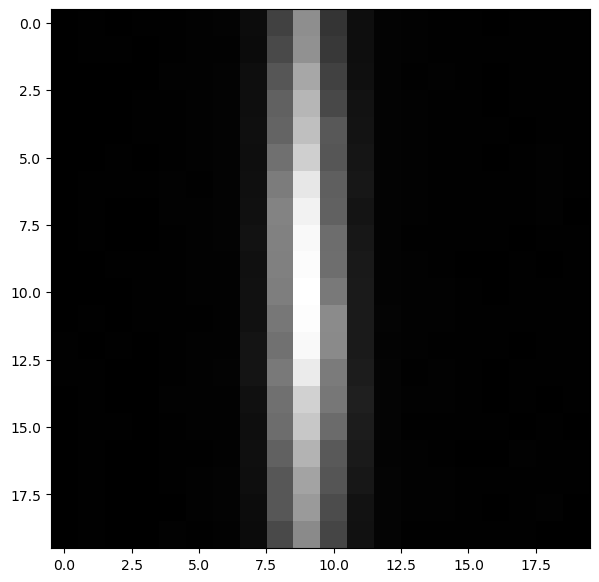

In [18]:
plt.imshow(test[8])

In [16]:
info = np.load(
    "/lustre/lrspec/ZTF_data/training_aug24/stamps_pos_trans/info/ztf_20221020138241_000686_zi_c08_x_0024._4_stamps_info.npy"
)

In [17]:
info

array([[ 2.  ,  3.  ],
       [ 1.05,  9.  ],
       [10.  ,  9.  ],
       [ 6.  ,  8.  ],
       [ 4.  ,  6.  ],
       [ 1.01,  5.  ],
       [ 3.  ,  3.  ],
       [ 4.  ,  4.  ],
       [ 3.  ,  6.  ],
       [ 6.  ,  5.  ]])